<!-- # Copyright (c) 2026 takotime808 -->
# Multi-Output Surrogates, Start to Finish

This tutorial walks through the core single-fidelity workflow on analytic benchmarks whose
true answer is known everywhere, so every step can be checked rather than taken on trust:

1. [Per-output model selection](#selection): `AutoDetectMultiOutputRegressor` picks a model
   for each output (ZDT1 and ZDT3).
2. [Explanations against a known answer](#explain): SHAP values and partial dependence on
   Friedman 1, where only five of the ten inputs matter.
3. [Uncertainty you can trust](#uq): a GP's intervals and conformal intervals on the
   non-stationary Gramacy & Lee function.
4. [Scoring a surrogate for optimization](#regret): Pareto-front regret on ZDT1, with the
   exact front from `zdt_front`.
5. [Summary and next steps](#summary)

All benchmarks come from `multioutreg.active.benchmarks`
(`get_benchmark(name)` returns the function, its bounds and a sampler). The whole notebook
runs in about two minutes.

In [1]:
import warnings

warnings.filterwarnings("ignore")  # GP optimizer convergence chatter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.inspection import PartialDependenceDisplay
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from multioutreg.active.benchmarks import get_benchmark, zdt_front
from multioutreg.conformal import SplitConformalPredictor
from multioutreg.metrics import front_hypervolume_regret, hypervolume_regret, pareto_mask
from multioutreg.model_selection import AutoDetectMultiOutputRegressor
from multioutreg.surrogates import GaussianProcessSurrogate
from multioutreg.surrogates.gp_sklearn import default_gp_kernel

# Plot styles: the true function is a wide pale band drawn underneath,
# models are thinner coloured lines on top, data points sit above both.
TRUTH = {"color": "0.8", "lw": 6, "zorder": 1, "solid_capstyle": "round"}
TRAIN = {"s": 30, "color": "black", "edgecolor": "white", "linewidth": 0.6, "zorder": 4}
BLUE, ORANGE, GREEN, PINK = "#0072B2", "#E69F00", "#009E73", "#CC79A7"


def r2(Y_true, Y_pred):
    # R^2 per output column.
    return 1 - ((Y_true - Y_pred) ** 2).sum(0) / ((Y_true - Y_true.mean(0)) ** 2).sum(0)


def model_name(est):
    # Readable name of a fitted estimator (the last step of a pipeline).
    return type(est.steps[-1][1] if hasattr(est, "steps") else est).__name__

<a id="selection"></a>
## 1. Per-output model selection

`AutoDetectMultiOutputRegressor` grid-searches every candidate on every output with the
same cross-validation folds and keeps the best one **per output**. Different outputs of the
same simulator are often very different problems, and one model family rarely suits all of
them.

ZDT1 and ZDT3 (Zitzler, Deb & Thiele 2000) make that concrete. Both have two outputs over
$x \in [0, 1]^6$:

- output 1 is $f_1 = x_1$, a plane;
- output 2 is $f_2 = g\,h(f_1 / g)$ with $g = 1 + \tfrac{9}{5}\sum_{i \ge 2} x_i$, which is
  curved in $x_1$ and, for ZDT3, oscillates with $\sin(10\pi x_1)$.

The candidate list below is short so the notebook runs quickly: a linear model, a GP, a
random forest, gradient boosting and KNN, with small grids. In practice,
`AutoDetectMultiOutputRegressor.with_vendored_surrogates()` searches 18 or more families,
which takes minutes rather than seconds on data this size; `pre_screen=True` skips families
the data does not justify. With `cv="auto"` (the default) the cross-validation scheme is
chosen from the number of rows: 80 rows gives 5-fold CV repeated 3 times.

In [2]:
def candidates():
    # (estimators, parameter grids) for AutoDetectMultiOutputRegressor.
    estimators = [
        LinearRegression(),
        make_pipeline(StandardScaler(), GaussianProcessRegressor(kernel=default_gp_kernel(), normalize_y=True)),
        RandomForestRegressor(n_estimators=200, random_state=0),
        GradientBoostingRegressor(random_state=0),
        make_pipeline(StandardScaler(), KNeighborsRegressor()),
    ]
    grids = [{}, {}, {"max_depth": [None, 6]}, {"max_depth": [2, 3]},
             {"kneighborsregressor__n_neighbors": [3, 7]}]
    return estimators, grids


fitted, test_sets, rows = {}, {}, []
for name in ["zdt1", "zdt3"]:
    bench = get_benchmark(name)                     # 6 inputs by default (n_features=...)
    X = bench.sample(80, method="lhs", seed=0)      # 80 training runs
    Y = bench(X)
    X_test = bench.sample(2000, method="random", seed=1)
    Y_test = bench(X_test)

    model = AutoDetectMultiOutputRegressor(*candidates()).fit(X, Y)
    fitted[name], test_sets[name] = model, (X_test, Y_test)
    scores = r2(Y_test, model.predict(X_test))
    for j, sel in enumerate(model.selection_scores_):
        ranked = sorted(sel.items(), key=lambda kv: -kv[1]["mean"])
        rows.append({
            "problem": name, "output": f"f{j + 1}",
            "chosen": model_name(model.models_[j]),
            "CV MSE (chosen)": -ranked[0][1]["mean"],
            "runner-up": f"{ranked[1][0]} ({-ranked[1][1]['mean']:.4f})",
            "held-out R²": scores[j],
        })

print("CV scheme:", fitted["zdt1"].cv_description_)
pd.DataFrame(rows).round(4)

CV scheme: Repeated 5-Fold CV (x3 repeats)


,problem,output,chosen,CV MSE (chosen),runner-up,held-out R²
0,zdt1,f1,LinearRegression,0.0000,gp (0.0000),1.0000
1,zdt1,f2,GaussianProcessRegressor,0.0057,linear (0.0169),0.9978
2,zdt3,f1,LinearRegression,0.0000,gp (0.0000),1.0000
3,zdt3,f2,GaussianProcessRegressor,0.1682,linear (0.1891),0.8509


**Reading the table.** On both problems the plane $f_1$ goes to the linear model, which fits
it exactly, and $f_2$ goes to the GP. For ZDT1 the GP's held-out $R^2$ on $f_2$ is close to 1.
For ZDT3, 80 runs are not enough to resolve the $\sin(10\pi x_1)$ oscillation in six
dimensions, and the GP's $R^2$ is clearly lower: the selection is right, but the data budget
is the limit. The `selection_scores_` attribute holds every candidate's cross-validated
score, so the margin between the winner and the runner-up is visible. The winner's CV score
is optimistically biased (it is the best of several); the held-out $R^2$ is the unbiased
number.

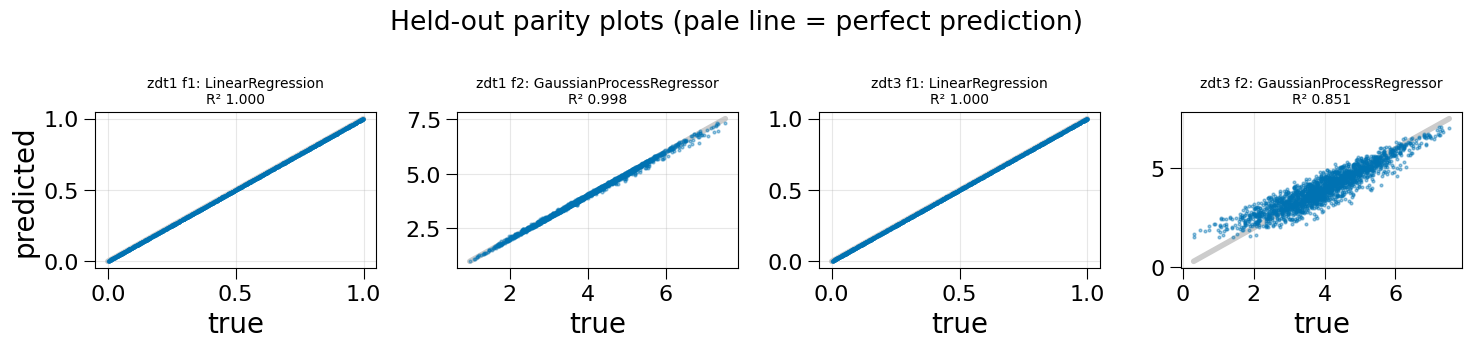

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for k, name in enumerate(["zdt1", "zdt3"]):
    X_test, Y_test = test_sets[name]
    P = fitted[name].predict(X_test)
    for j in range(2):
        ax = axes[2 * k + j]
        lims = [Y_test[:, j].min(), Y_test[:, j].max()]
        ax.plot(lims, lims, **{**TRUTH, "lw": 4})
        ax.scatter(Y_test[:, j], P[:, j], s=4, alpha=0.4, color=BLUE, zorder=2)
        ax.set_title(f"{name} f{j + 1}: {model_name(fitted[name].models_[j])}\nR² {r2(Y_test, P)[j]:.3f}", fontsize=10)
        ax.set_xlabel("true")
        ax.grid(alpha=0.3)
axes[0].set_ylabel("predicted")
fig.suptitle("Held-out parity plots (pale line = perfect prediction)")
fig.tight_layout()
plt.show()

<a id="explain"></a>
## 2. Explanations against a known answer

SHAP values and partial-dependence plots are only useful if they find the inputs that
actually drive the output. Friedman 1 (Friedman 1991) is the standard check:

$$y = 10 \sin(\pi x_1 x_2) + 20 (x_3 - 0.5)^2 + 10 x_4 + 5 x_5 + \varepsilon,
\qquad x \in [0, 1]^{10},$$

so $x_6, \dots, x_{10}$ have **no effect at all**. The usual benchmark adds
$\varepsilon \sim N(0, 1)$ noise, as here, with 200 training runs.

chosen model: GaussianProcessRegressor | CV: 10-Fold CV (shuffled)
held-out R² against the noise-free function: 0.903


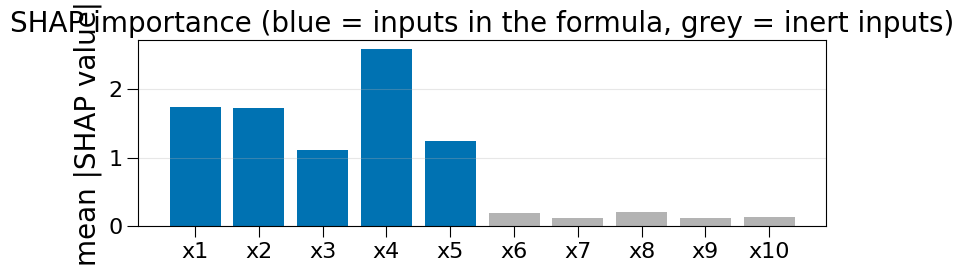

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10
mean |SHAP|,1.732,1.72,1.104,2.581,1.241,0.192,0.119,0.2,0.118,0.135


In [4]:
bench = get_benchmark("friedman1")
X_f = bench.sample(200, method="lhs", seed=0)
Y_f = bench(X_f) + np.random.default_rng(0).normal(0, 1, (200, 1))
X_ft = bench.sample(2000, method="random", seed=1)
Y_ft = bench(X_ft)                                  # noise-free truth for scoring

friedman = AutoDetectMultiOutputRegressor(*candidates()).fit(X_f, Y_f)
feature_names = [f"x{i}" for i in range(1, 11)]
print("chosen model:", model_name(friedman.models_[0]), "| CV:", friedman.cv_description_)
print(f"held-out R² against the noise-free function: {r2(Y_ft, friedman.predict(X_ft))[0]:.3f}")

# KernelExplainer works with any model; 10 k-means centres summarise the background data.
explainer = shap.KernelExplainer(lambda Z: friedman.predict(Z)[:, 0], shap.kmeans(X_f, 10))
shap_values = explainer.shap_values(X_f[:80], nsamples=300, silent=True)
importance = pd.Series(np.abs(shap_values).mean(0), index=feature_names)

fig, ax = plt.subplots(figsize=(8, 3))
colors = [BLUE] * 5 + ["0.7"] * 5
ax.bar(feature_names, importance.values, color=colors)
ax.set_ylabel("mean |SHAP value|")
ax.set_title("SHAP importance (blue = inputs in the formula, grey = inert inputs)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()
importance.round(3).to_frame("mean |SHAP|").T

**Reading the result.** The five inputs in the formula have importances several times those
of the five inert ones. The inert inputs are not exactly zero: the model was fitted to noisy
data and has learned a little spurious structure, so a small importance is not evidence that
an input matters. $x_4$ ranks first because its effect is linear with the largest range
(0 to 10).

Partial dependence shows the *shape* of each effect: linear in $x_4$ and $x_5$, a parabola
in $x_3$ with its minimum at 0.5, and flat for $x_6, \dots, x_{10}$.
`multioutreg.figures.pdp_plots.generate_pdp_plot` and
`multioutreg.figures.shap_multioutput.generate_shap_plot` produce the versions of these
figures used in the HTML report; the latter uses SHAP's exact explainer, which takes over a
minute on ten inputs.

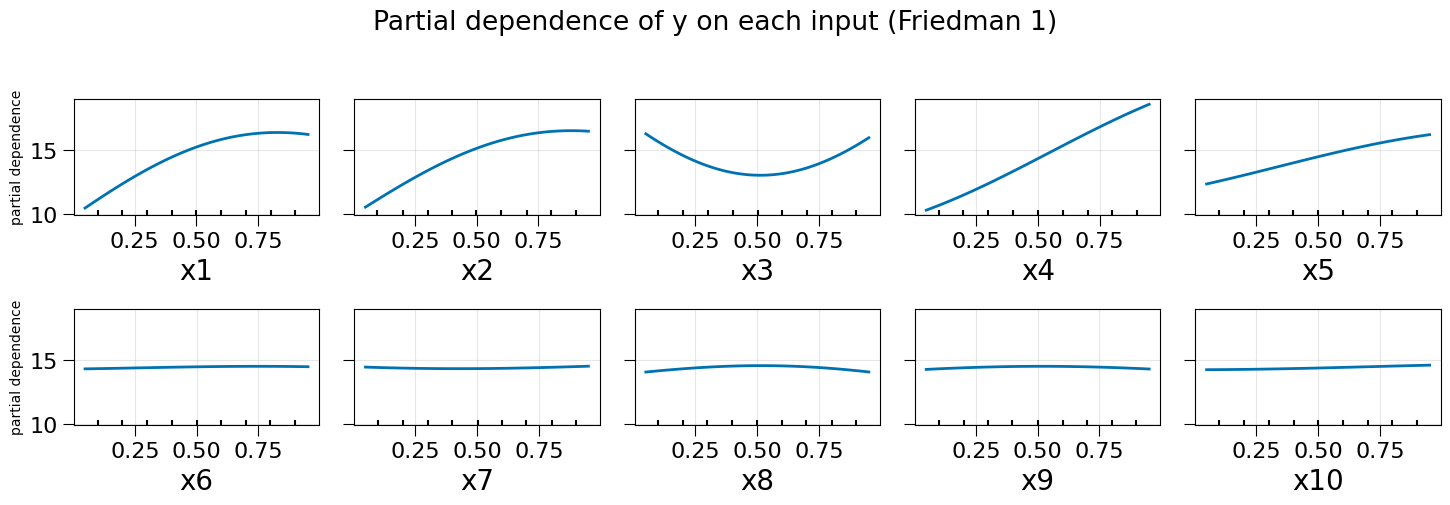

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(15, 5.2), sharey=True)
PartialDependenceDisplay.from_estimator(
    friedman.estimators_[0], X_f, features=range(10), feature_names=feature_names,
    ax=axes.ravel(), line_kw={"color": BLUE, "lw": 2},
)
for k, ax in enumerate(axes.ravel()):
    ax.set_ylabel("partial dependence" if k % 5 == 0 else "", fontsize=10)
    ax.grid(alpha=0.3)
fig.suptitle("Partial dependence of y on each input (Friedman 1)")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

<a id="uq"></a>
## 3. Uncertainty you can trust

A surrogate's intervals are only useful if they contain the truth about as often as they
claim. The Gramacy & Lee (2012) function on $[0.5, 2.5]$,

$$f(x) = \frac{\sin(10\pi x)}{2x} + (x - 1)^4,$$

oscillates quickly on the left and is smooth on the right. A stationary GP has one length
scale for the whole range, so its error and its claimed uncertainty cannot both be right on
both sides. 60 noisy runs ($\sigma = 0.05$) are used, and coverage is measured separately on
the wiggly part ($x < 1$) and the smooth part.

Three kinds of 90% interval are compared:

- the GP's own band, mean ± 1.645σ, from `GaussianProcessSurrogate.predict(return_std=True)`;
- **split conformal** (`SplitConformalPredictor`), which holds out 30% of the runs, takes the
  90% quantile of their absolute residuals, and adds that constant width everywhere;
- **adaptive split conformal** (`adaptive=True`), which scales the width by the model's σ.

In [6]:
bench = get_benchmark("gramacy_lee")
X_g = bench.sample(60, method="random", seed=0)
Y_g = bench(X_g) + np.random.default_rng(0).normal(0, 0.05, (60, 1))
x_grid = np.linspace(0.5, 2.5, 400)[:, None]
y_grid = bench(x_grid)
wiggly = x_grid[:, 0] < 1.0

gp = GaussianProcessSurrogate().fit(X_g, Y_g)
mu, sd = gp.predict(x_grid, return_std=True)
bands = {"GP band (mean ± 1.645σ)": (mu - 1.645 * sd, mu + 1.645 * sd)}

# SplitConformalPredictor clones its estimator, so it takes a scikit-learn regressor.
for label, adaptive in [("split conformal", False), ("adaptive split conformal", True)]:
    cp = SplitConformalPredictor(
        GaussianProcessRegressor(kernel=default_gp_kernel(), normalize_y=True),
        calibration_size=0.3, adaptive=adaptive, random_state=0,
    ).fit(X_g, Y_g)
    lo, hi = cp.predict_interval(x_grid, alpha=0.1)
    bands[label] = (np.reshape(lo, (-1, 1)), np.reshape(hi, (-1, 1)))

rows = []
for label, (lo, hi) in bands.items():
    inside = ((y_grid >= lo) & (y_grid <= hi)).ravel()
    width = (hi - lo).ravel()
    rows.append({"interval": label, "coverage (all)": inside.mean(),
                 "coverage x < 1": inside[wiggly].mean(), "coverage x ≥ 1": inside[~wiggly].mean(),
                 "width x < 1": width[wiggly].mean(), "width x ≥ 1": width[~wiggly].mean()})
pd.DataFrame(rows).set_index("interval").round(3)

,coverage (all),coverage x < 1,coverage x ≥ 1,width x < 1,width x ≥ 1
interval,,,,,
GP band (mean ± 1.645σ),0.938,0.75,1.0,1.121,1.109
split conformal,0.962,0.85,1.0,1.235,1.235
adaptive split conformal,0.965,0.86,1.0,1.252,1.239


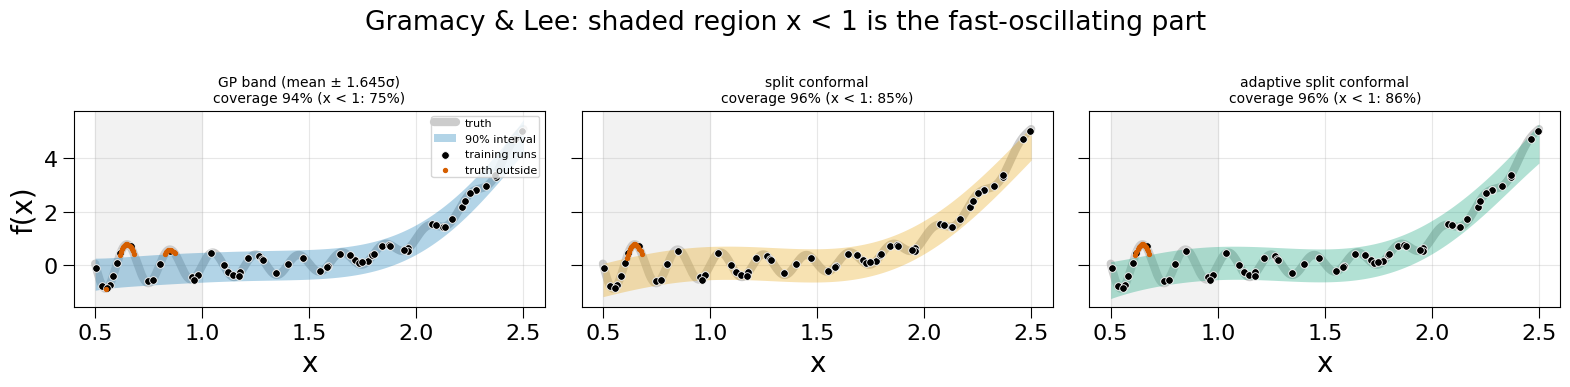

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (label, (lo, hi)), color in zip(axes, bands.items(), [BLUE, ORANGE, GREEN]):
    ax.axvspan(0.5, 1.0, color="0.95", zorder=0)
    ax.plot(x_grid, y_grid, **TRUTH, label="truth")
    ax.fill_between(x_grid.ravel(), lo.ravel(), hi.ravel(), color=color, alpha=0.3, lw=0, zorder=2, label="90% interval")
    ax.scatter(X_g, Y_g, **TRAIN, label="training runs")
    inside = ((y_grid >= lo) & (y_grid <= hi)).ravel()
    ax.scatter(x_grid[~inside], y_grid[~inside], s=8, color="#D55E00", zorder=5, label="truth outside")
    ax.set_title(f"{label}\ncoverage {inside.mean():.0%} (x < 1: {inside[wiggly].mean():.0%})", fontsize=10)
    ax.set_xlabel("x")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("f(x)")
axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("Gramacy & Lee: shaded region x < 1 is the fast-oscillating part")
fig.tight_layout()
plt.show()

**Reading the result.**

- **The GP's own band** misses most often on the wiggly side, where its error is largest, and
  covers everything on the smooth side. Its σ depends on the distance to the nearest training
  run, not on how hard the function is there, so it cannot know that the left is harder.
- **Split conformal** guarantees the *overall* rate: on average at least 90% of new points
  from the same distribution fall inside (96% here). It sizes one constant width from the
  held-out residuals, which raises coverage on the wiggly side (75% → 85%) but not to 90%,
  while the smooth side, already fully covered, gets no narrower. The guarantee is
  **marginal** (averaged over $x$), not conditional on $x$.
- **Adaptive conformal** can only reshape the interval as well as the model's σ tracks the
  error. A stationary GP's σ is nearly flat on this design (the GP band is about 1.1 wide on
  both sides), so the adaptive version looks much like the plain one.

In practice: check coverage by region (or by output, or by predicted value) and not only
overall. Conditional problems call for a model whose uncertainty can vary with $x$
(heteroscedastic or non-stationary models, tree ensembles' spread) or for more data where the
function is hard, which is what variance-based active learning provides (see the
[active learning tutorial](active_learning_benchmarks.ipynb)).

<a id="regret"></a>
## 4. Scoring a surrogate for optimization

When the outputs are objectives to be minimized together, the question is not only "how
accurate is the surrogate?" but "**would it lead to good designs?**" The ZDT1 surrogate from
section 1 is used to screen 2,000 candidate designs: the candidates it predicts to be
Pareto-optimal are the ones an engineer would run next.

Decision regret measures what that choice costs, using the **true** objective values:

$$\text{regret} = \mathrm{HV}\big(\text{front of } Y_\text{true}\big) -
\mathrm{HV}\big(\text{front of } Y_\text{true}[\text{model's picks}]\big) \;\ge 0,$$

where HV is the hypervolume dominated by a front up to a reference point (larger is better).
`hypervolume_regret(Y_true, Y_pred)` computes exactly this: the picks are
`pareto_mask(Y_pred)`, and `Y_true` and `Y_pred` hold the same candidates, row for row.

`front_hypervolume_regret(Y_true, Y_pred)` instead compares the *predicted* front with the true
one, $\mathrm{HV}(\text{front}(Y_\text{true})) - \mathrm{HV}(\text{front}(Y_\text{pred}))$. That measures how well the front's position is predicted, not
whether the picks are good, and because the difference is clipped at zero, a model that is
simply **optimistic** (predicts every design to be better than it is) can score zero.

In [8]:
bench = get_benchmark("zdt1")
model = fitted["zdt1"]
X_cand = bench.sample(2000, method="random", seed=7)
Y_cand = bench(X_cand)                       # true objectives of every candidate
P_cand = model.predict(X_cand)               # what the surrogate predicts
ref = np.array([1.1, 1.1 * Y_cand[:, 1].max()])

picks = pareto_mask(P_cand)                  # candidates the surrogate calls Pareto-optimal
optimistic = P_cand - np.array([0.0, 0.5])   # same ranking, every f2 predicted 0.5 too low
rng = np.random.default_rng(0)
random_picks = rng.choice(len(Y_cand), picks.sum(), replace=False)

table = pd.DataFrame({
    "decision regret (true values at the picks)": {
        "surrogate": hypervolume_regret(Y_cand, P_cand, reference_point=ref),
        "optimistic surrogate": hypervolume_regret(Y_cand, optimistic, reference_point=ref),
        # no predictions here, so score the true values of the random picks as a front
        f"{picks.sum()} random candidates": front_hypervolume_regret(Y_cand, Y_cand[random_picks], reference_point=ref),
    },
    "front_hypervolume_regret(Y_true, Y_pred)": {
        "surrogate": front_hypervolume_regret(Y_cand, P_cand, reference_point=ref),
        "optimistic surrogate": front_hypervolume_regret(Y_cand, optimistic, reference_point=ref),
        f"{picks.sum()} random candidates": np.nan,
    },
})
print(f"surrogate picks {picks.sum()} of {len(X_cand)} candidates; "
      f"{(pareto_mask(Y_cand) & picks).sum()} of the {pareto_mask(Y_cand).sum()} truly Pareto-optimal candidates are among them")
table.round(4)

surrogate picks 14 of 2000 candidates; 13 of the 13 truly Pareto-optimal candidates are among them


,decision regret (true values at the picks),"front_hypervolume_regret(Y_true, Y_pred)"
surrogate,0.0000,0.0417
optimistic surrogate,0.0000,0.0000
14 random candidates,1.7691,NaN


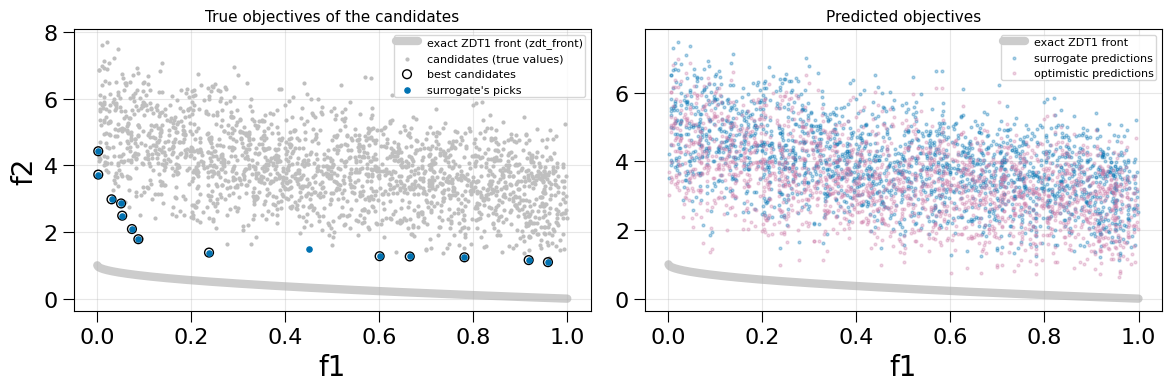

In [9]:
front = zdt_front("zdt1")
true_best = pareto_mask(Y_cand)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)

ax = axes[0]
ax.plot(front[:, 0], front[:, 1], **TRUTH, label="exact ZDT1 front (zdt_front)")
ax.scatter(Y_cand[:, 0], Y_cand[:, 1], s=4, color="0.75", zorder=2, label="candidates (true values)")
ax.scatter(Y_cand[true_best, 0], Y_cand[true_best, 1], s=40, facecolor="none", edgecolor="black", zorder=3, label="best candidates")
ax.scatter(Y_cand[picks, 0], Y_cand[picks, 1], s=14, color=BLUE, zorder=4, label="surrogate's picks")
ax.set_title("True objectives of the candidates", fontsize=11)
ax.set_xlabel("f1"); ax.set_ylabel("f2")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(front[:, 0], front[:, 1], **TRUTH, label="exact ZDT1 front")
ax.scatter(P_cand[:, 0], P_cand[:, 1], s=4, color=BLUE, alpha=0.3, zorder=2, label="surrogate predictions")
ax.scatter(optimistic[:, 0], optimistic[:, 1], s=4, color=PINK, alpha=0.3, zorder=2, label="optimistic predictions")
ax.set_title("Predicted objectives", fontsize=11)
ax.set_xlabel("f1")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Reading the result.** The surrogate's 14 picks include all 13 truly best candidates, so its
decision regret is zero, against a large regret for the same number of random picks. The optimistic surrogate ranks the candidates identically, so its decision regret is
the same: it would lead to the same designs. The predicted-front comparison tells a different
story: it charges the accurate surrogate for small errors in the front's position, and gives
the optimistic one a perfect score of zero, because its predicted front dominates the true
one and the difference is clipped.

Use decision regret (true values at the picks) to judge a surrogate for optimization. Note
that these candidates are random designs, which lie well above the exact ZDT1 front (left
panel); regret is measured against the best of the candidates, not against the exact front.

<a id="summary"></a>
## 5. Summary and next steps

| Step | What to use | What the benchmark showed |
|---|---|---|
| Model selection | `AutoDetectMultiOutputRegressor` (`with_vendored_surrogates()` for the full search, `pre_screen=True` to prune it) | Different outputs of one problem get different models; the held-out score, not the CV score of the winner, is the honest number |
| Explanations | SHAP values, partial dependence on `model.estimators_[j]` | The five active Friedman inputs stand far above the five inert ones; small importances can be noise |
| Uncertainty | `predict(return_std=True)`, `SplitConformalPredictor` | Conformal intervals fix overall coverage, not coverage where the function is hard; check coverage by region |
| Optimization | `pareto_mask`, `hypervolume_regret(Y_true, Y_pred)` | Score the designs the model would pick, using their true values |

**Next steps**

- The [cost-savings tutorial](cost_savings.ipynb) prices what a surrogate saves in simulator
  runs; the [active learning tutorial](active_learning_benchmarks.ipynb) chooses the training
  runs instead of fixing them up front.
- `multioutreg.report.auto_detect_report.generate_html_report` and the Streamlit GUI
  (`streamlit run multioutreg/gui/Grid_Search_Surrogate_Models.py`) turn a fitted model into
  an HTML report with these figures.
- More benchmarks are listed in `multioutreg.active.benchmarks.BENCHMARKS`.

**References**

- Zitzler, E., Deb, K., & Thiele, L. (2000). Comparison of multiobjective evolutionary
  algorithms: empirical results. *Evolutionary Computation*, 8(2).
- Friedman, J. H. (1991). Multivariate adaptive regression splines. *Annals of Statistics*,
  19(1).
- Gramacy, R. B., & Lee, H. K. H. (2012). Cases for the nugget in modeling computer
  experiments. *Statistics and Computing*, 22(3).
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model
  predictions. *NeurIPS*.
- Lei, J., G'Sell, M., Rinaldo, A., Tibshirani, R. J., & Wasserman, L. (2018).
  Distribution-free predictive inference for regression. *JASA*, 113(523).